Mounting the GDrive data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Accessing the data set

In [2]:
from pathlib import Path

import pandas as pd

root = Path('/content/drive/MyDrive/Colab-Notebooks/vTuber/vTuber1B ')
channels = pd.read_csv(root / 'channels.csv')
chat = pd.read_csv(root / 'chat_stats.csv')
superchat = pd.read_csv(root / 'superchat_stats.csv')

coverage = chat.merge(
    superchat,
    on=['channelId', 'period'],
    how='outer',
    validate='one_to_one',
    indicator='coverage',
)
analysis = coverage.loc[coverage['coverage'].ne('right_only')].merge(
    channels[['channelId', 'affiliation']],
    on='channelId',
    how='left',
    validate='many_to_one',
)
analysis['period'] = pd.to_datetime(analysis['period'], format='%Y-%m')
matched = analysis.loc[analysis['coverage'].eq('both')]
rho = matched['uniqueChatters'].corr(matched['superChats'], method='spearman')
print(coverage['coverage'].value_counts().to_string())
print(f'Chat observations: {len(analysis):,}  |  Spearman rho: {rho:.3f}')

coverage
both          10941
left_only      1527
right_only        1
Chat observations: 12,468  |  Spearman rho: 0.723


Explorasi data


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import NullFormatter

# Using 'root' defined from the earlier cell
folder = root
kunci = ["channelId", "period"]

chat_bab2 = pd.read_csv(
    folder / "chat_stats.csv", usecols=kunci + ["uniqueChatters"]
)
superchat_bab2 = pd.read_csv(
    folder / "superchat_stats.csv", usecols=kunci + ["superChats"]
)

pasangan = chat_bab2.merge(
    superchat_bab2, on=kunci, how="inner", validate="one_to_one"
)
pasangan = pasangan.loc[pasangan["period"].between("2021-03", "2022-07")]
data = pasangan[["uniqueChatters", "superChats"]]

print("Jumlah pengamatan berpasangan:", len(data))

Jumlah pengamatan berpasangan: 10941


Tabel Statistik deskriptif pengamatan berpasangan

In [4]:
stat_desc = pd.DataFrame({
    "Jumlah pengamatan": data.count(),
    "Rata-rata": data.mean().round(2),
    "Median": data.median(),
    "Modus": data.apply(
        lambda kolom: " dan ".join(str(int(nilai)) for nilai in kolom.mode())
    ),
    "Simpangan baku": data.std(ddof=1).round(2),
    "Varians": data.var(ddof=1).round(2),
    "Minimum": data.min(),
    "Maksimum": data.max(),
}).T.rename(columns={
    "uniqueChatters": "Pengguna unik live chat",
    "superChats": "Super Chat tercatat",
})

display(stat_desc)

,Pengguna unik live chat,Super Chat tercatat
Jumlah pengamatan,10941,10941
Rata-rata,5794.06,529.01
Median,1399.0,163.0
Modus,131 dan 156,1
Simpangan baku,12043.0,1323.8
Varians,145033775.77,1752441.99
Minimum,3,1
Maksimum,224155,49855


Distribusi pengguna unik live chat dan Super Chat

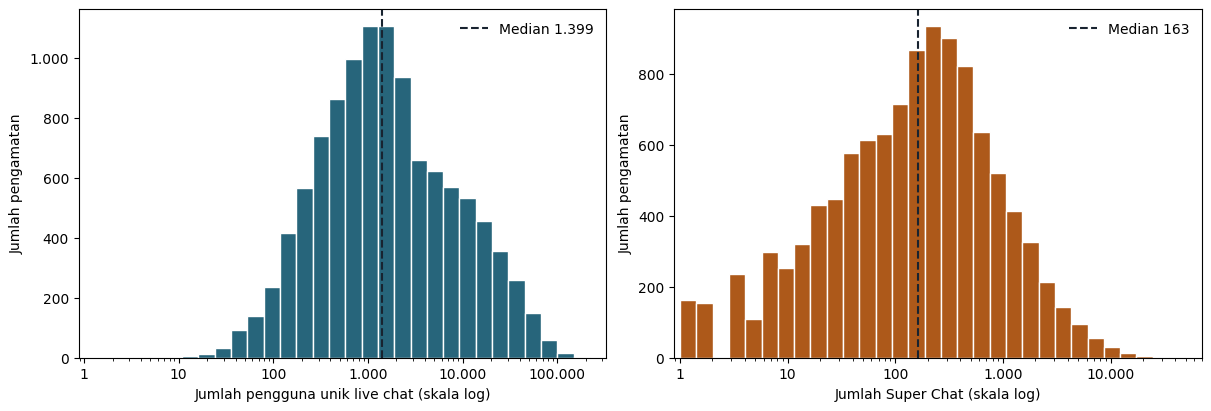

In [5]:
def angka_id(nilai, posisi=None):
    return f"{int(nilai):,}".replace(",", ".")

panel = [
    ("uniqueChatters", "Jumlah pengguna unik live chat", "#27657b", 330_000),
    ("superChats", "Jumlah Super Chat", "#ad591a", 70_000),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for ax, (kolom, label, warna, batas) in zip(axes, panel):
    nilai = data[kolom]
    bins = np.geomspace(1, batas, 33)
    ax.hist(nilai, bins=bins, color=warna, edgecolor="white")

    median = nilai.median()
    ax.axvline(
        median, color="#182330", linestyle="--",
        label=f"Median {angka_id(median)}",
    )
    ax.set(
        xscale="log", xlim=(0.88, batas),
        xlabel=f"{label} (skala log)", ylabel="Jumlah pengamatan",
    )
    ax.xaxis.set_major_formatter(angka_id)
    ax.yaxis.set_major_formatter(angka_id)
    ax.legend(frameon=False)

fig.savefig(folder / "Gambar_2_1.png", dpi=250, facecolor="white")
plt.show()

Hubungan pengguna unik live chat dan Super Chat

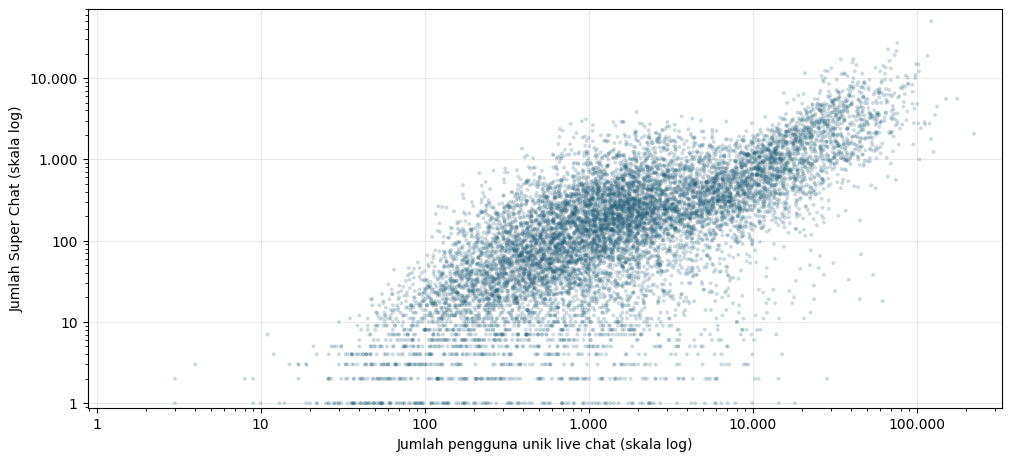

Korelasi Spearman: 0,723


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")

ax.scatter(
    data["uniqueChatters"], data["superChats"],
    s=8, color="#18566e", alpha=0.21, edgecolors="none",
)
ax.set(
    xscale="log", yscale="log",
    xlim=(0.88, 330_000), ylim=(0.88, 70_000),
    xlabel="Jumlah pengguna unik live chat (skala log)",
    ylabel="Jumlah Super Chat (skala log)",
)
ax.xaxis.set_major_formatter(angka_id)
ax.yaxis.set_major_formatter(angka_id)
ax.set_axisbelow(True)
ax.grid(which="major", alpha=0.25)

fig.savefig(folder / "Gambar_2_2.png", dpi=250, facecolor="white")
plt.show()

rho = data["uniqueChatters"].corr(data["superChats"], method="spearman")
print("Korelasi Spearman:", f"{rho:.3f}".replace(".", ","))

Missing data

In [7]:
jumlah_hilang = analysis.isna().sum()
ringkasan_hilang = pd.DataFrame({
    "Jumlah hilang": jumlah_hilang,
    "Persentase (%)": (100 * jumlah_hilang / len(analysis)).round(2),
}).rename_axis("Kolom")
display(ringkasan_hilang.sort_values("Jumlah hilang", ascending=False, kind="stable"))

print("Sel kosong di chat_stats.csv:", chat.isna().sum().sum())
print("Sel kosong di superchat_stats.csv:", superchat.isna().sum().sum())
print("Nilai group kosong di channels.csv:", channels["group"].isna().sum())

,Jumlah hilang,Persentase (%)
Kolom,,
superChats,1527,12.25
uniqueSuperChatters,1527,12.25
totalSC,1527,12.25
averageSC,1527,12.25
totalMessageLength,1527,12.25
averageMessageLength,1527,12.25
mostFrequentCurrency,1527,12.25
mostFrequentColor,1527,12.25
affiliation,28,0.22


Sel kosong di chat_stats.csv: 0
Sel kosong di superchat_stats.csv: 0
Nilai group kosong di channels.csv: 929


Pola missing value

In [8]:
superchat_hilang = analysis["superChats"].isna()
status_superchat = superchat_hilang.map({
    False: "Super Chat tercatat",
    True: "Super Chat belum diketahui",
})

ringkasan_status = analysis.groupby(status_superchat)["uniqueChatters"].agg(
    jumlah_pengamatan="size",
    median_pengguna_unik="median",
)
display(ringkasan_status)

kuartil = pd.qcut(
    analysis["uniqueChatters"], q=4, labels=["Q1", "Q2", "Q3", "Q4"]
)
ringkasan_kuartil = (
    analysis.assign(kuartil=kuartil, superchat_hilang=superchat_hilang)
    .groupby("kuartil", observed=True)
    .agg(
        jumlah_pengamatan=("superchat_hilang", "size"),
        jumlah_hilang=("superchat_hilang", "sum"),
        pengguna_unik_min=("uniqueChatters", "min"),
        pengguna_unik_maks=("uniqueChatters", "max"),
    )
)
ringkasan_kuartil["Persentase (%)"] = (
    100 * ringkasan_kuartil["jumlah_hilang"]
    / ringkasan_kuartil["jumlah_pengamatan"]
).round(2)
display(ringkasan_kuartil)

,jumlah_pengamatan,median_pengguna_unik
superChats,,
Super Chat belum diketahui,1527,356.0
Super Chat tercatat,10941,1399.0


,jumlah_pengamatan,jumlah_hilang,pengguna_unik_min,pengguna_unik_maks,Persentase (%)
kuartil,,,,,
Q1,3119,788,1.0,405.0,25.26
Q2,3118,309,406.0,1241.0,9.91
Q3,3114,272,1242.0,4314.0,8.73
Q4,3117,158,4317.0,224155.0,5.07


Visualize

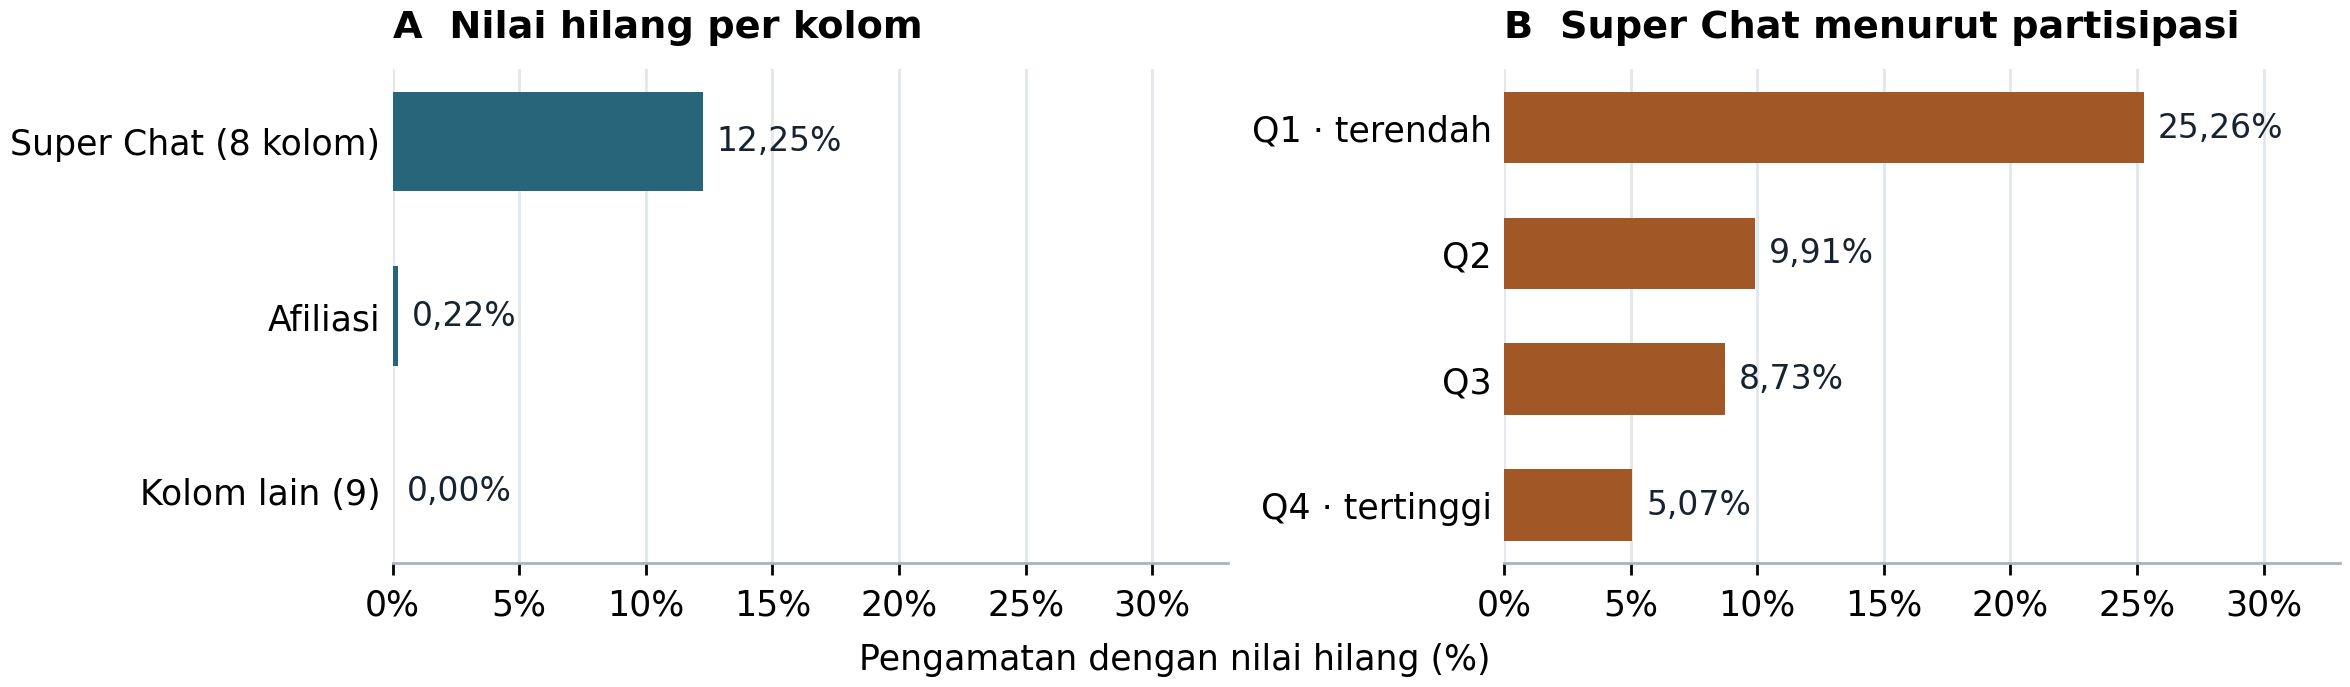

In [9]:
from matplotlib.ticker import PercentFormatter
from IPython.display import Image, display

def diagram_persen(ax, label, persen, judul, warna):
    batang = ax.barh(label, persen, color=warna, height=0.57)
    teks = [f"{nilai:.2f}%".replace(".", ",") for nilai in persen]
    ax.bar_label(batang, labels=teks, padding=4, color="#182330", fontsize=9.5)
    ax.invert_yaxis()
    ax.set_xlim(0, 33)
    ax.set_xticks(range(0, 31, 5))
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_title(judul, loc="left", fontsize=11, fontweight="bold", pad=9)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#e1e7eb", linewidth=0.8)
    ax.tick_params(axis="y", length=0)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#aab4bf")

fig, (kiri, kanan) = plt.subplots(
    1, 2, figsize=(9.4, 2.75), layout="constrained",
)
diagram_persen(
    kiri,
    ["Super Chat (8 kolom)", "Afiliasi", "Kolom lain (9)"],
    [
        ringkasan_hilang.loc["superChats", "Persentase (%)"],
        ringkasan_hilang.loc["affiliation", "Persentase (%)"],
        0,
    ],
    "A  Nilai hilang per kolom", "#27657b",
)
diagram_persen(
    kanan,
    ["Q1 · terendah", "Q2", "Q3", "Q4 · tertinggi"],
    ringkasan_kuartil["Persentase (%)"].tolist(),
    "B  Super Chat menurut partisipasi", "#a15726",
)
fig.supxlabel("Pengamatan dengan nilai hilang (%)", fontsize=10)
gambar = folder / "Gambar_4_1_Nilai_Hilang.png"
fig.savefig(gambar, dpi=250, facecolor="white")
plt.close(fig)
display(Image(filename=str(gambar), width=900))

eliminate

In [10]:
kolom_utama = ["uniqueChatters", "superChats"]
matched = analysis.dropna(subset=kolom_utama).copy()
jumlah_dikecualikan = len(analysis) - len(matched)

print("Pengamatan pada tabel analysis:", len(analysis))
print("Pengamatan untuk korelasi:", len(matched))
print("Pengamatan di luar subset korelasi:", jumlah_dikecualikan)
print("Pasangan dengan afiliasi belum diketahui:", matched["affiliation"].isna().sum())

rho = matched["uniqueChatters"].corr(matched["superChats"], method="spearman")
print("Korelasi Spearman:", f"{rho:.3f}".replace(".", ","))

Pengamatan pada tabel analysis: 12468
Pengamatan untuk korelasi: 10941
Pengamatan di luar subset korelasi: 1527
Pasangan dengan afiliasi belum diketahui: 21
Korelasi Spearman: 0,723


imputate

In [11]:
afiliasi_tampilan = analysis["affiliation"].astype("string").fillna("Tidak diketahui")
print("Pengamatan dengan label Tidak diketahui:", afiliasi_tampilan.eq("Tidak diketahui").sum())
print("Hitungan Super Chat yang belum diketahui:", analysis["superChats"].isna().sum())

Pengamatan dengan label Tidak diketahui: 28
Hitungan Super Chat yang belum diketahui: 1527


Analisa desk

In [12]:
nama_variabel = {
    "uniqueChatters": "Pengguna unik live chat",
    "superChats": "Super Chat tercatat",
}
numerik = analysis[list(nama_variabel)]
moda = numerik.apply(
    lambda kolom: " dan ".join(str(int(nilai)) for nilai in kolom.mode())
)
tabel_5_1 = pd.DataFrame({
    "Jumlah pengamatan": numerik.count(),
    "Rata-rata": numerik.mean().round(2),
    "Median (Q2)": numerik.median(),
    "Modus": moda,
    "Simpangan baku": numerik.std(ddof=1).round(2),
    "Varians": numerik.var(ddof=1).round(2),
    "Minimum": numerik.min(),
    "Kuartil pertama (Q1)": numerik.quantile(0.25),
    "Kuartil ketiga (Q3)": numerik.quantile(0.75),
    "Maksimum": numerik.max(),
}).T.rename(columns=nama_variabel)
display(tabel_5_1)

,Pengguna unik live chat,Super Chat tercatat
Jumlah pengamatan,12468,10941
Rata-rata,5365.06,529.01
Median (Q2),1241.0,163.0
Modus,1,1
Simpangan baku,11595.82,1323.8
Varians,134463132.49,1752441.99
Minimum,1.0,1.0
Kuartil pertama (Q1),405.0,40.0
Kuartil ketiga (Q3),4314.75,471.0
Maksimum,224155.0,49855.0


skewness kurtosis

In [13]:
bentuk_distribusi = pd.DataFrame({
    "Skewness": numerik.skew(),
    "Kurtosis berlebih": numerik.kurt(),
}).rename(index=nama_variabel)
display(bentuk_distribusi.round(2))

,Skewness,Kurtosis berlebih
Pengguna unik live chat,4.88,37.60
Super Chat tercatat,10.61,237.42


Histogram

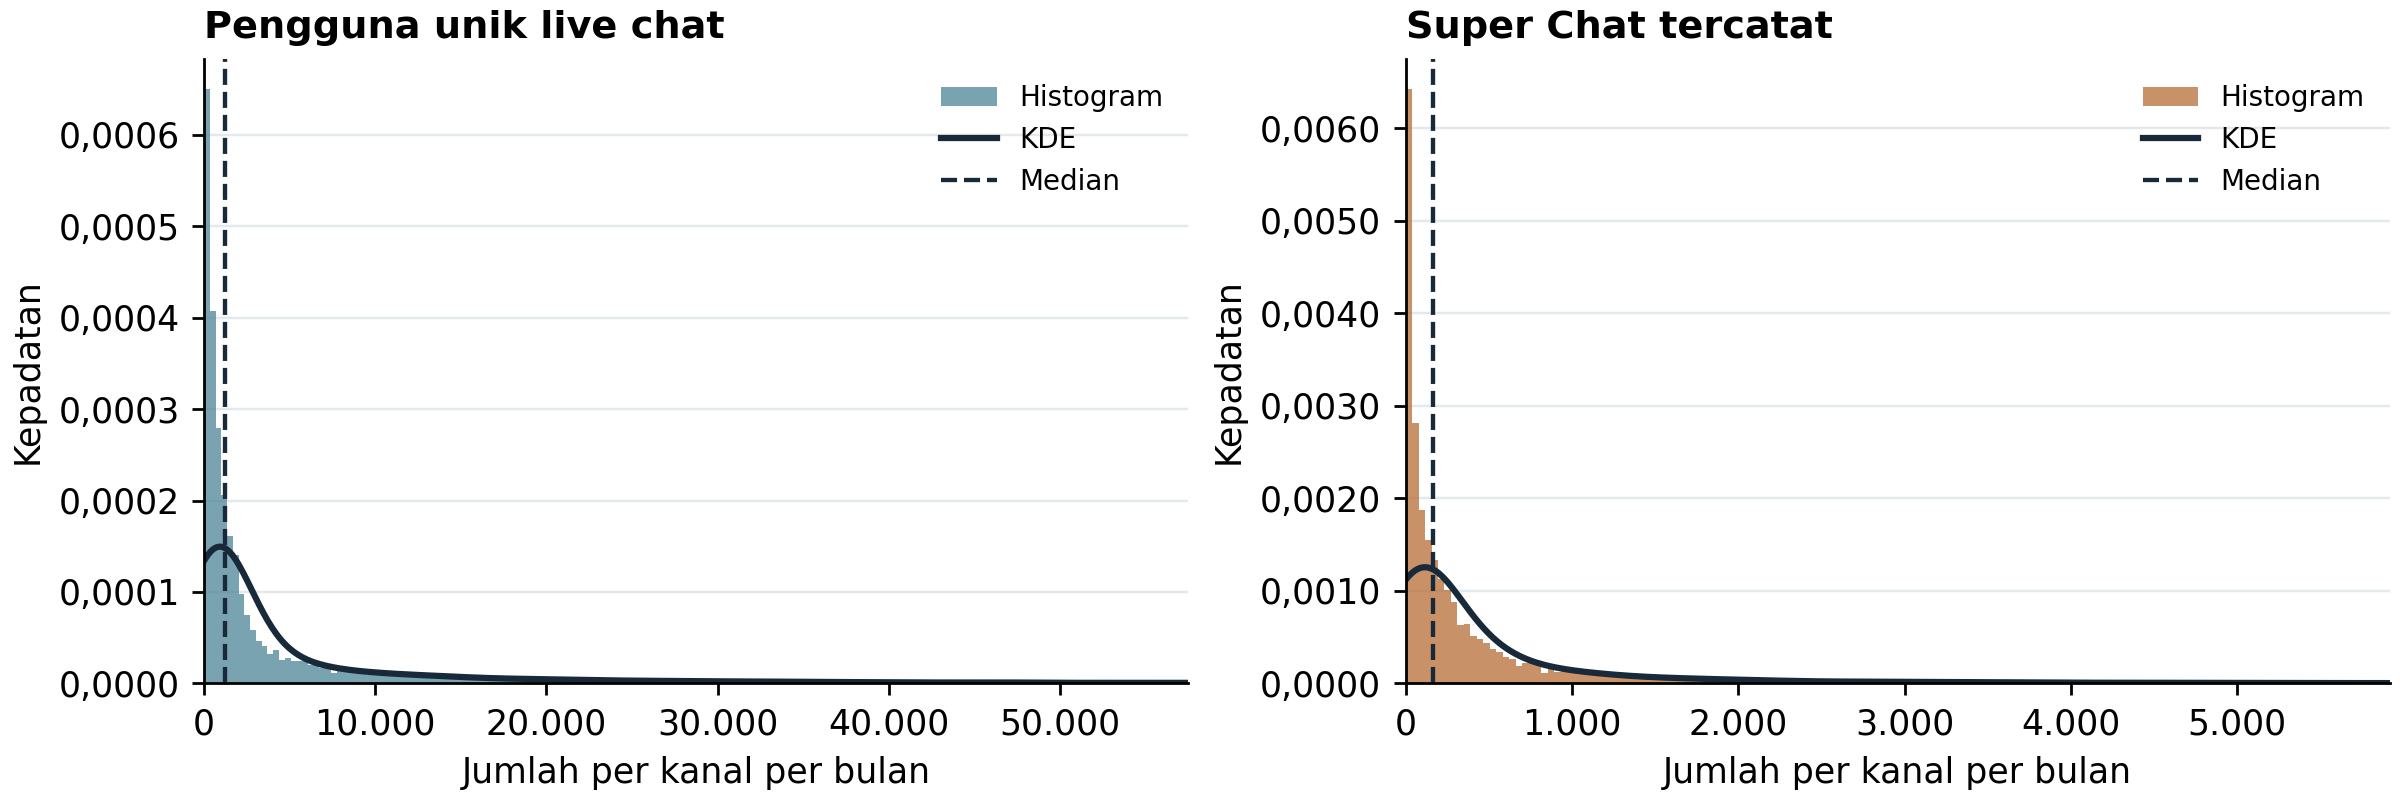

In [14]:
from matplotlib.ticker import FuncFormatter
from scipy.stats import gaussian_kde

warna_histogram = {
    "uniqueChatters": "#4A8396",
    "superChats": "#B66B34",
}
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2), layout="constrained")

for ax, (kolom, judul) in zip(axes, nama_variabel.items()):
    nilai = numerik[kolom].dropna().to_numpy(dtype=float)
    p99 = np.quantile(nilai, 0.99)
    x = np.linspace(0, p99, 450)

    ax.hist(
        nilai, bins="fd", density=True, color=warna_histogram[kolom],
        alpha=0.74, label="Histogram",
    )
    ax.plot(x, gaussian_kde(nilai)(x), color="#182A3A", lw=1.8, label="KDE")
    ax.axvline(np.median(nilai), color="#182A3A", ls="--", lw=1.25, label="Median")
    ax.set_title(judul, loc="left", fontsize=11, fontweight="bold")
    ax.set(xlabel="Jumlah per kanal per bulan", ylabel="Kepadatan", xlim=(0, p99))
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda nilai, _: f"{nilai:,.0f}".replace(",", "."))
    )
    ax.yaxis.set_major_formatter(FuncFormatter(lambda nilai, _: f"{nilai:.4f}".replace(".", ",")))
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E3E9EC", lw=0.7)
    ax.legend(loc="upper right", frameon=False, fontsize=8)

gambar = folder / "Gambar_5_1_Histogram_KDE.png"
fig.savefig(gambar, dpi=250, facecolor="white")
plt.close(fig)
display(Image(filename=str(gambar), width=900))

perbandingan before dan after

In [15]:
nama_variabel = {
    "uniqueChatters": "Pengguna unik live chat",
    "superChats": "Super Chat tercatat",
}
numerik = analysis[list(nama_variabel)].astype(float)
log_data = np.log1p(numerik)

tabel_6_1 = pd.DataFrame({
    "Skewness asli": numerik.skew(),
    "Skewness log1p": log_data.skew(),
    "Kurtosis berlebih asli": numerik.kurt(),
    "Kurtosis berlebih log1p": log_data.kurt(),
}).rename(index=nama_variabel).rename_axis("Variabel")
display(tabel_6_1.round(2))

,Skewness asli,Skewness log1p,Kurtosis berlebih asli,Kurtosis berlebih log1p
Variabel,,,,
Pengguna unik live chat,4.88,-0.12,37.60,0.11
Super Chat tercatat,10.61,-0.22,237.42,-0.34


histogram


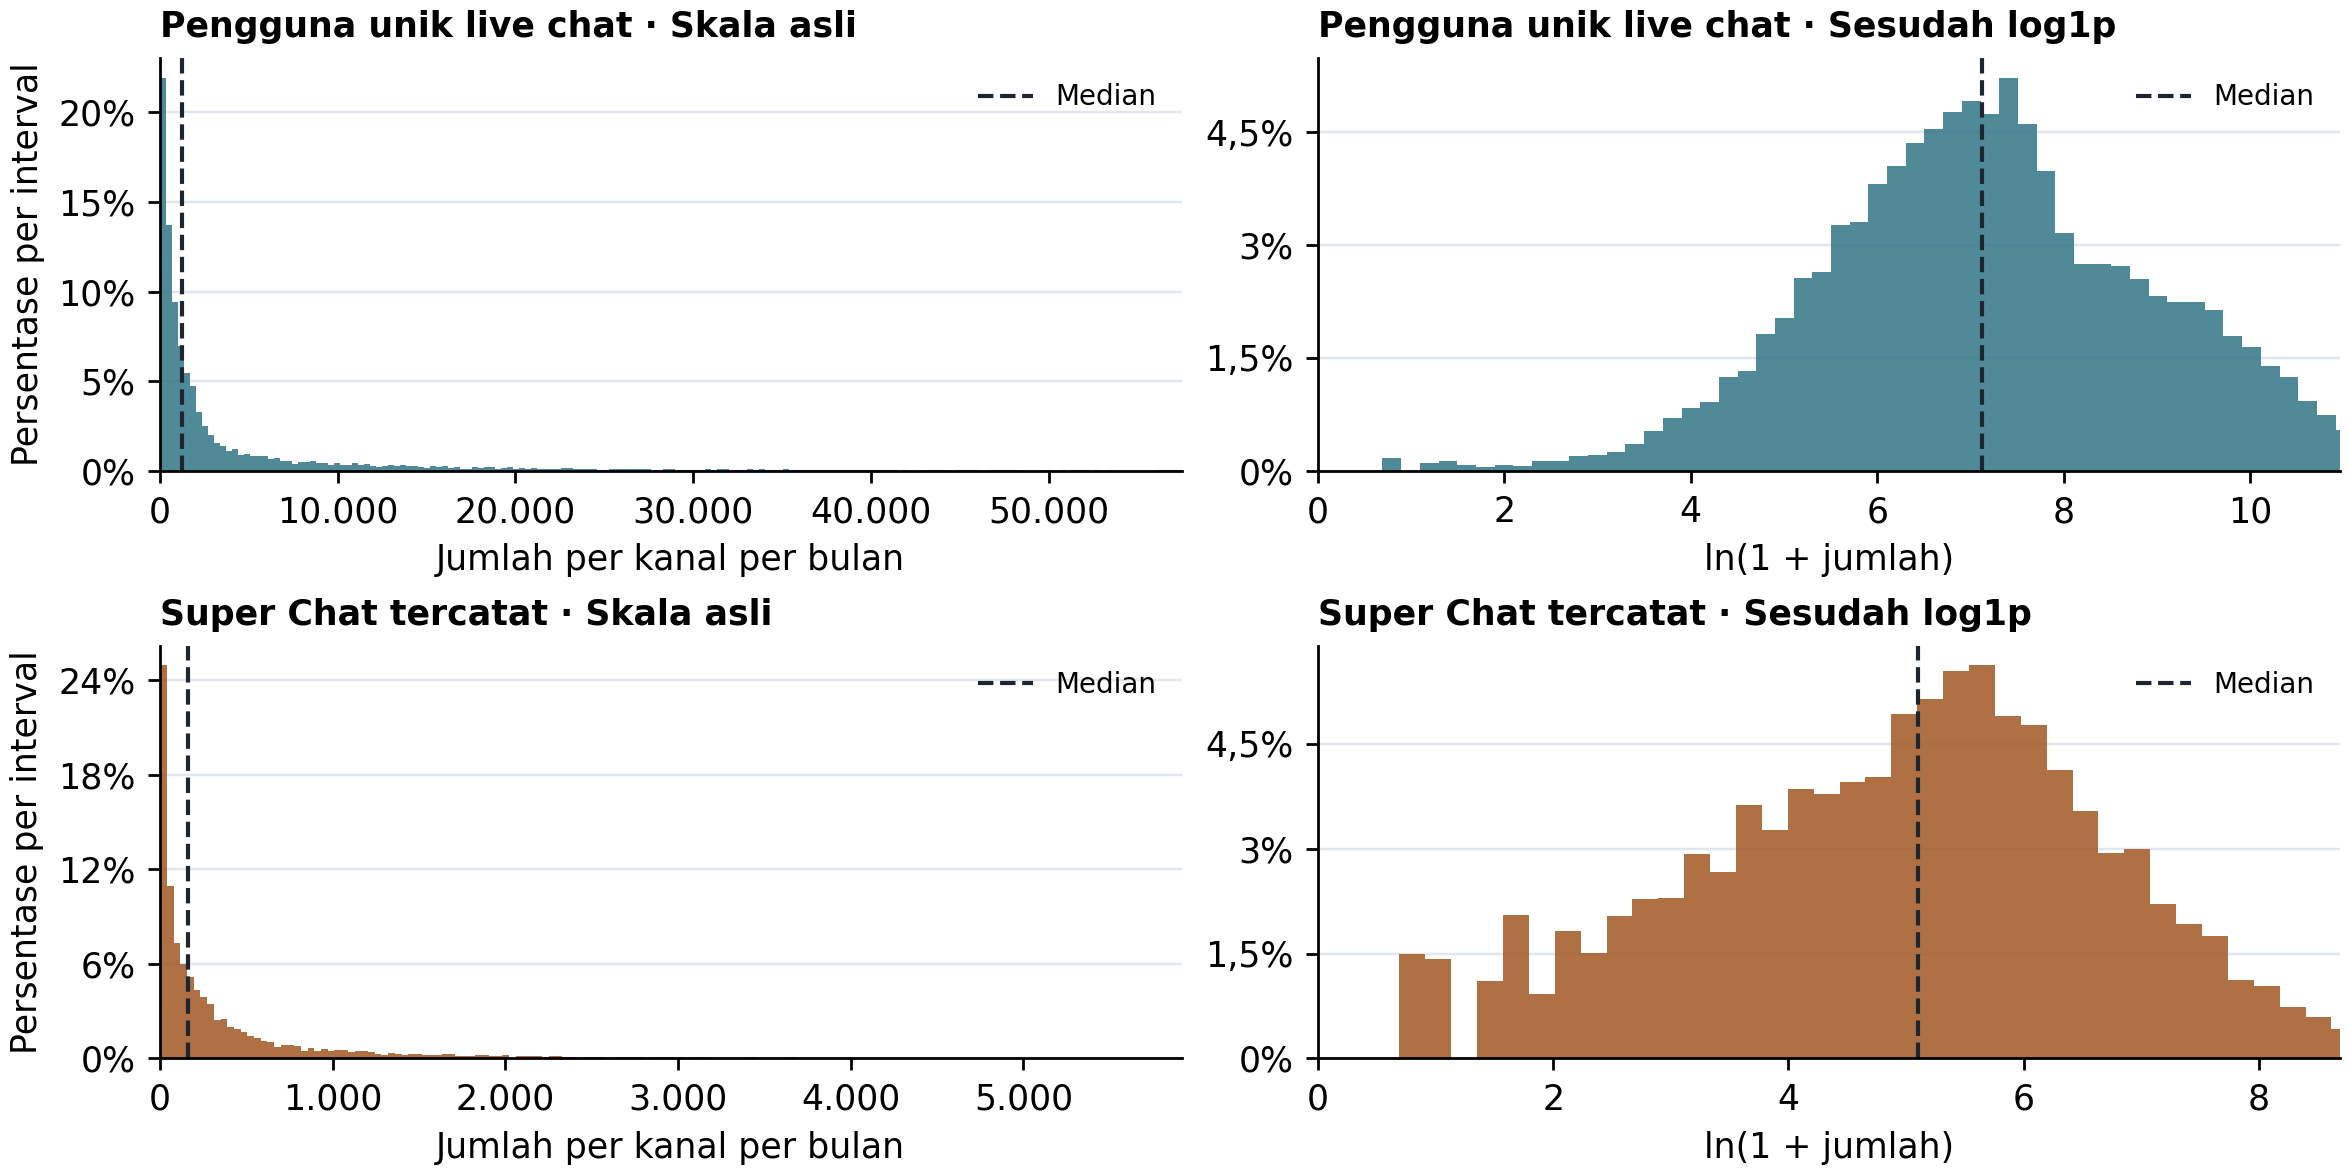

In [16]:
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy.stats import gaussian_kde

def format_persen(nilai, _):
    teks = f"{100 * nilai:.1f}".removesuffix(".0")
    return teks.replace(".", ",") + "%"


warna = {"uniqueChatters": "#367789", "superChats": "#A35B28"}
fig, axes = plt.subplots(2, 2, figsize=(9.4, 4.7), layout="constrained")

for baris, (kolom, nama) in enumerate(nama_variabel.items()):
    asli = numerik[kolom].dropna().to_numpy()
    log = log_data[kolom].dropna().to_numpy()
    batas = np.quantile(asli, 0.99)
    panel = [
        (asli, batas, "Skala asli", "Jumlah per kanal per bulan"),
        (log, np.log1p(batas), "Sesudah log1p", "ln(1 + jumlah)"),
    ]

    for ax, (nilai, batas_kanan, judul, label_x) in zip(axes[baris], panel):
        tepi = np.histogram_bin_edges(nilai, bins="fd")
        ax.hist(
            nilai, bins=tepi, weights=np.full(len(nilai), 1 / len(nilai)),
            color=warna[kolom], alpha=0.87, edgecolor="none",
        )
        ax.axvline(np.median(nilai), color="#1D2630", ls="--", lw=1.2, label="Median")
        ax.set_title(f"{nama} · {judul}", loc="left", fontsize=10, fontweight="bold")
        ax.set(xlim=(0, batas_kanan), xlabel=label_x)
        ax.yaxis.set_major_formatter(FuncFormatter(format_persen))
        ax.yaxis.set_major_locator(MaxNLocator(5))
        ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
        ax.xaxis.set_major_formatter(
            FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
        )
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="#E1E7EC", lw=0.7)
        ax.legend(loc="upper right", frameon=False, fontsize=8)
    axes[baris, 0].set_ylabel("Persentase per interval")

gambar = folder / "Gambar_6_1_Transformasi_Log.png"
fig.savefig(gambar, dpi=250, facecolor="white")
plt.close(fig)
display(Image(filename=str(gambar), width=900))

SCALER standar & minMAX

In [17]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaler_standar = StandardScaler()
scaler_minmaks = MinMaxScaler()

standar = pd.DataFrame(
    scaler_standar.fit_transform(log_data),
    index=log_data.index, columns=log_data.columns,
)
minmaks = pd.DataFrame(
    scaler_minmaks.fit_transform(log_data),
    index=log_data.index, columns=log_data.columns,
)

def ringkas_skala(frame):
    return pd.DataFrame({
        "Rata-rata": frame.mean(),
        "Simpangan baku (ddof=0)": frame.std(ddof=0),
        "Minimum": frame.min(),
        "Maksimum": frame.max(),
    }).rename(index=nama_variabel)

tabel_6_2 = pd.concat({
    "StandardScaler": ringkas_skala(standar),
    "MinMaxScaler": ringkas_skala(minmaks),
}, names=["Metode", "Variabel"])
display(tabel_6_2.round(2) + 0.0)

jumlah_hilang = pd.DataFrame({
    "Skala asli": numerik.isna().sum(),
    "Sesudah log1p": log_data.isna().sum(),
    "StandardScaler": standar.isna().sum(),
    "MinMaxScaler": minmaks.isna().sum(),
}).rename(index=nama_variabel)
display(jumlah_hilang)

Rata-rata  Simpangan baku (ddof=0)  \
Metode         Variabel                                                      
StandardScaler Pengguna unik live chat       0.00                     1.00   
               Super Chat tercatat           0.00                     1.00   
MinMaxScaler   Pengguna unik live chat       0.56                     0.15   
               Super Chat tercatat           0.42                     0.18   

                                        Minimum  Maksimum  
Metode         Variabel                                    
StandardScaler Pengguna unik live chat    -3.63      2.88  
               Super Chat tercatat        -2.37      3.30  
MinMaxScaler   Pengguna unik live chat     0.00      1.00  
               Super Chat tercatat         0.00      1.00

,Skala asli,Sesudah log1p,StandardScaler,MinMaxScaler
Pengguna unik live chat,0,0,0,0
Super Chat tercatat,1527,1527,1527,1527


variable Numerric

,Pengguna unik live chat,Super Chat tercatat
count,12468.0,10941.0
min,1.0,1.0
50%,1241.0,163.0
max,224155.0,49855.0


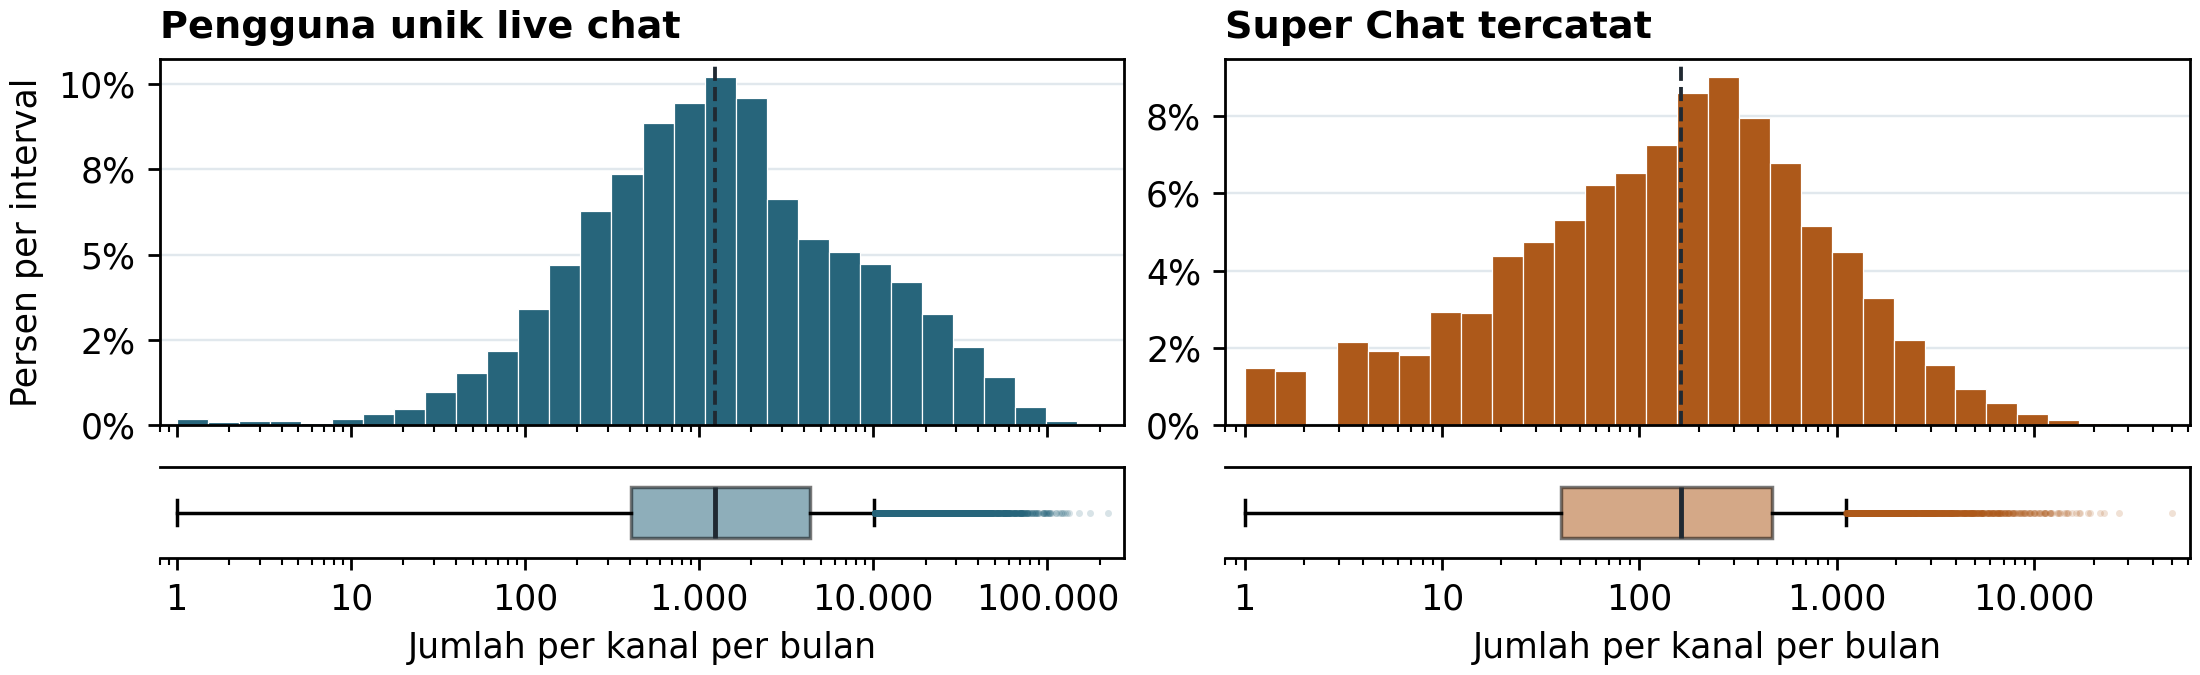

In [18]:
from matplotlib.ticker import PercentFormatter, LogFormatter

# Define missing colors based on previous cells
biru = "#27657b"
jingga = "#ad591a"

# Define missing helper functions
def format_log(xaxis):
    def angka_id(nilai, posisi=None):
        return f"{int(nilai):,}".replace(",", ".")
    xaxis.set_major_formatter(angka_id)

def simpan_gambar(fig, nama_file):
    gambar = folder / nama_file
    fig.savefig(gambar, dpi=250, facecolor="white")
    plt.close(fig)
    display(Image(filename=str(gambar), width=900))

label_numerik = {"uniqueChatters": "Pengguna unik live chat", "superChats": "Super Chat tercatat"}
ringkasan_numerik = analysis[list(label_numerik)].describe().loc[["count", "min", "50%", "max"]]
display(ringkasan_numerik.rename(columns=label_numerik))
fig, axes = plt.subplots(2, 2, figsize=(8.8, 2.7), sharex="col",
                         gridspec_kw={"height_ratios": [4, 1]}, layout="constrained")
for indeks, ((kolom, label), warna) in enumerate(zip(label_numerik.items(), (biru, jingga))):
    nilai = analysis[kolom].dropna().to_numpy(dtype=float)
    histogram, box = axes[:, indeks]
    tepi = np.geomspace(nilai.min(), nilai.max(), num=31)
    histogram.hist(nilai, bins=tepi, weights=np.full(len(nilai), 1 / len(nilai)),
                   color=warna, edgecolor="white", linewidth=0.35)
    histogram.set_title(label, loc="left", fontweight="bold", fontsize=11)
    histogram.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    histogram.axvline(np.median(nilai), color="#202932", linestyle="--", linewidth=1.1)
    histogram.set_axisbelow(True)
    histogram.grid(axis="y", color="#E1E8ED", linewidth=0.7)
    box.boxplot(nilai, orientation="horizontal", widths=0.55, whis=1.5, patch_artist=True,
                boxprops={"facecolor": warna, "alpha": 0.52},
                medianprops={"color": "#202932", "linewidth": 1.4},
                flierprops={"marker": ".", "markersize": 2, "alpha": 0.18, "markeredgecolor": warna})
    box.set(xscale="log", xlim=(0.8, nilai.max() * 1.23), yticks=[], xlabel="Jumlah per kanal per bulan")
    box.spines["left"].set_visible(False)
    format_log(box.xaxis)
axes[0, 0].set_ylabel("Persen per interval")
simpan_gambar(fig, "Gambar_7_1_Distribusi_Numerik.png")

Variable Categorical


,Pengamatan,Persentase
Independents,4139,33.20
Nijisanji,2613,20.96
Hololive,1076,8.63
774inc,435,3.49
ReAcT,326,2.61
Afiliasi lainnya,3851,30.89
Tidak diketahui,28,0.22


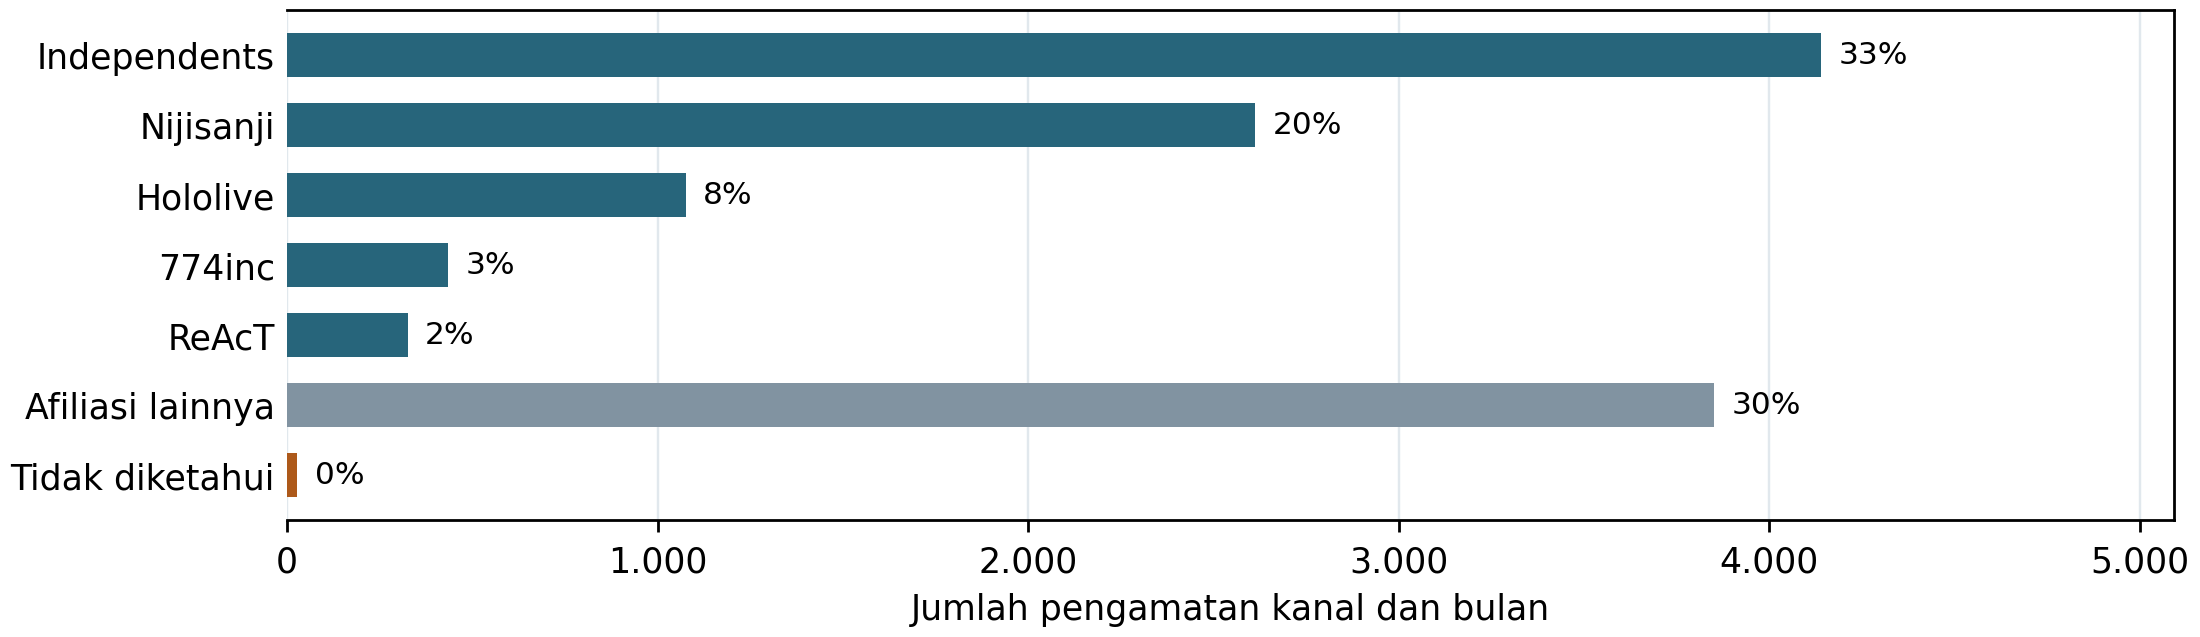

In [19]:
frekuensi = analysis["affiliation"].value_counts()
afiliasi_utama = frekuensi.head(5).index.tolist()
jumlah_hilang_afiliasi = int(analysis["affiliation"].isna().sum())
frekuensi_grafik = pd.concat([
    frekuensi.loc[afiliasi_utama],
    pd.Series({"Afiliasi lainnya": frekuensi.iloc[5:].sum(),
               "Tidak diketahui": jumlah_hilang_afiliasi}),
])
ringkasan_afiliasi = pd.DataFrame({
    "Pengamatan": frekuensi_grafik,
    "Persentase": 100 * frekuensi_grafik / len(analysis),
})
display(ringkasan_afiliasi.round(2))
fig, ax = plt.subplots(figsize=(8.8, 2.55), layout="constrained")
batang = ax.barh(frekuensi_grafik.index, frekuensi_grafik.to_numpy(), height=0.63,
                 color=[biru] * len(afiliasi_utama) + ["#8193A1", jingga])
labels = [f"{angka_id(persen, 2)}%" for persen in ringkasan_afiliasi["Persentase"]]
ax.bar_label(batang, labels=labels, padding=5, fontsize=9)
ax.set(xlabel="Jumlah pengamatan kanal dan bulan",
       xlim=(0, frekuensi_grafik.max() * 1.23))
ax.xaxis.set_major_formatter(FuncFormatter(lambda nilai, _: angka_id(nilai)))
ax.invert_yaxis()
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E1E8ED", linewidth=0.7)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
simpan_gambar(fig, "Gambar_7_2_Frekuensi_Afiliasi.png")

numerik vs numerik

,jumlah,median_pengguna,median_super_chat
uniqueChatters,,,
Q1,2745,240.0,27.0
Q2,2727,855.0,109.0
Q3,2734,2310.0,231.0
Q4,2735,13129.0,770.0


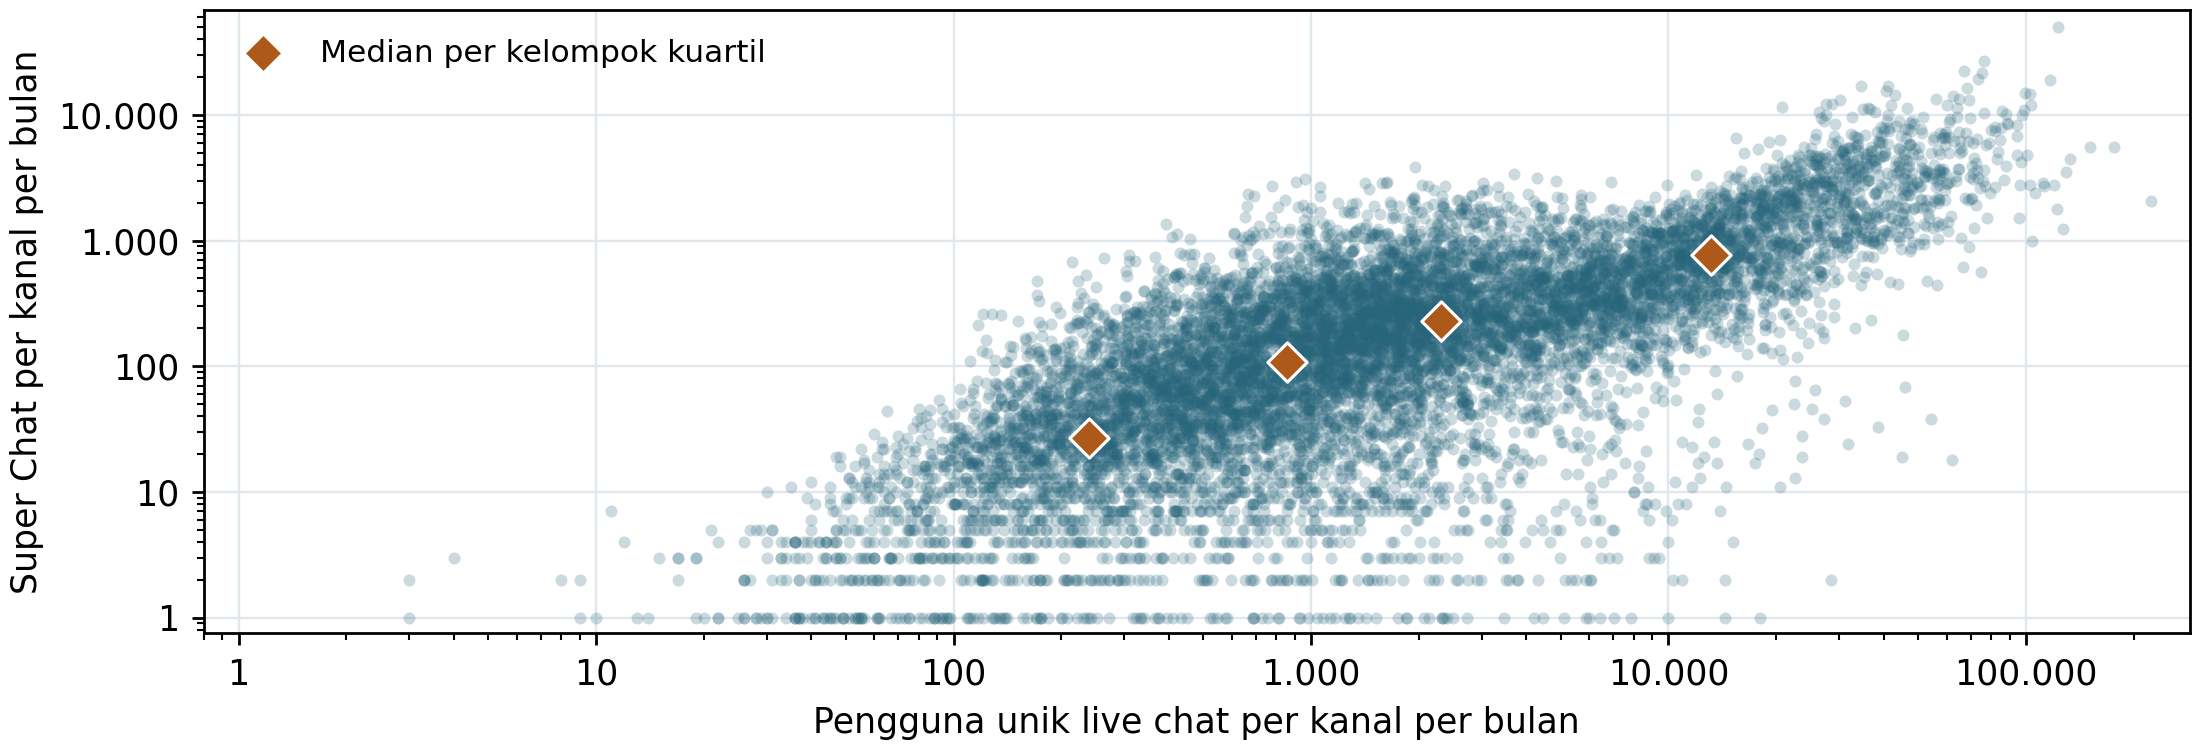

In [20]:
pasangan = analysis.dropna(subset=["uniqueChatters", "superChats"])
kuartil = pd.qcut(pasangan["uniqueChatters"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
median_kuartil = pasangan.groupby(kuartil, observed=True).agg(
    jumlah=("superChats", "size"), median_pengguna=("uniqueChatters", "median"),
    median_super_chat=("superChats", "median"),
)
display(median_kuartil)
fig, ax = plt.subplots(figsize=(8.8, 3.0), layout="constrained")
ax.scatter(pasangan["uniqueChatters"], pasangan["superChats"],
           s=12, alpha=0.24, color=biru, linewidths=0)
ax.scatter(median_kuartil["median_pengguna"], median_kuartil["median_super_chat"],
           s=64, marker="D", color=jingga, edgecolor="white", linewidth=0.9,
           zorder=3, label="Median per kelompok kuartil")
ax.set(xscale="log", yscale="log", xlim=(0.8, pasangan.uniqueChatters.max() * 1.28),
       ylim=(0.75, pasangan.superChats.max() * 1.36),
       xlabel="Pengguna unik live chat per kanal per bulan",
       ylabel="Super Chat per kanal per bulan")
format_log(ax.xaxis)
format_log(ax.yaxis)
ax.set_axisbelow(True)
ax.grid(color="#E1E8ED", linewidth=0.7)
ax.legend(loc="upper left", frameon=False, fontsize=9)
simpan_gambar(fig, "Gambar_7_3_Diagram_Pencar.png")

kategorikal vs numerik

,jumlah,median,q1,q3
affiliation,,,,
Independents,3647,71.0,21.0,218.00
Nijisanji,2466,243.0,64.0,669.75
Hololive,1000,1343.0,517.0,3013.50
774inc,411,255.0,133.5,445.50
ReAcT,297,81.0,27.0,218.00


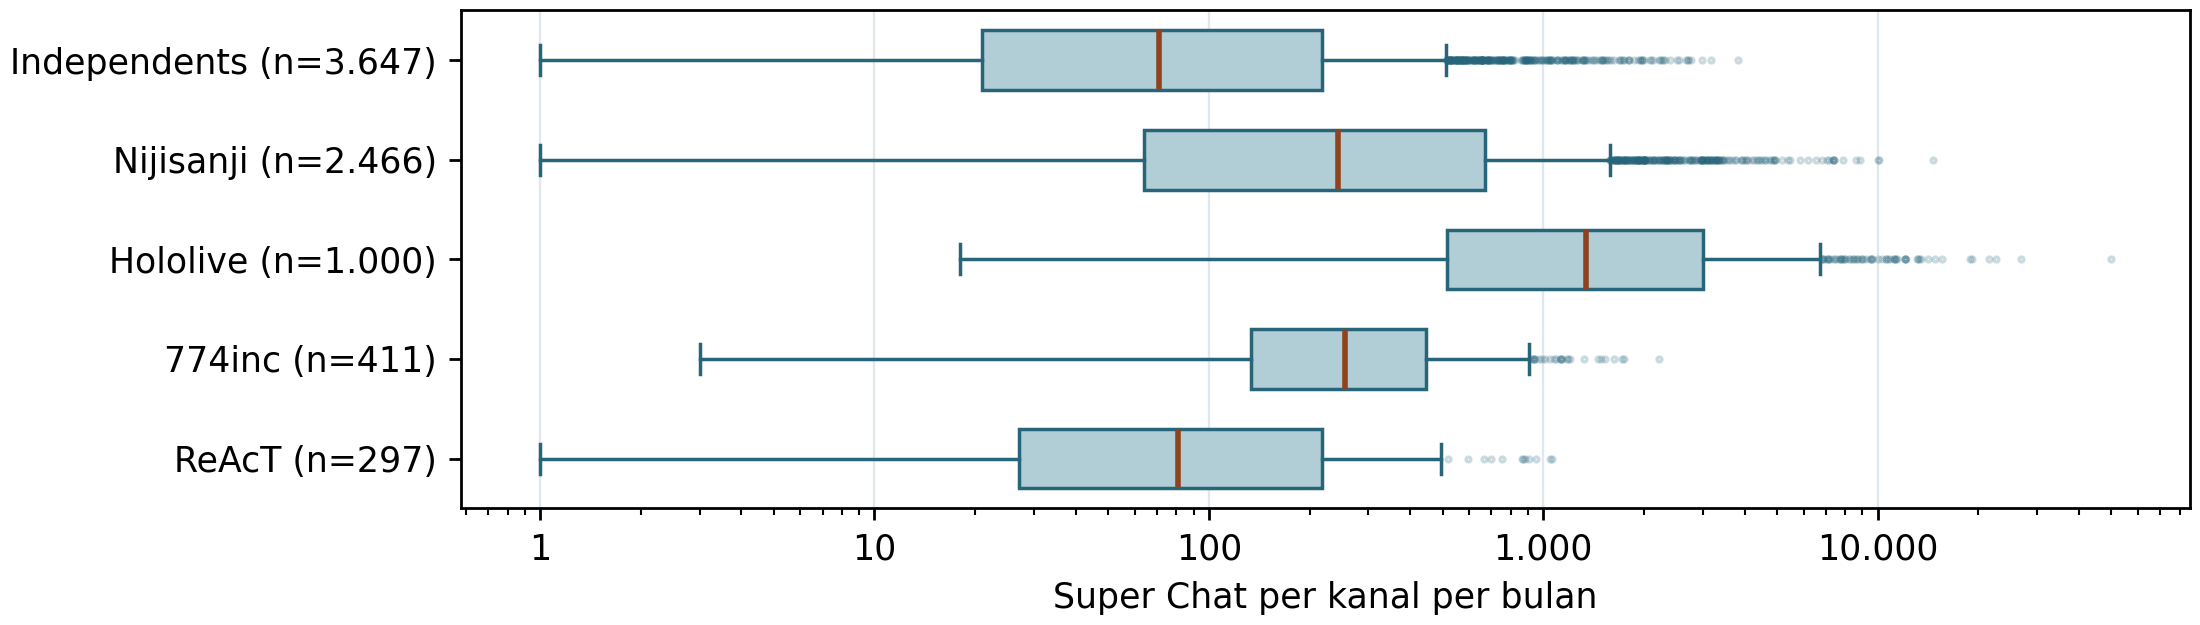

In [21]:
data_boxplot = analysis.loc[
    analysis["affiliation"].isin(afiliasi_utama) & analysis["superChats"].notna(),
    ["affiliation", "superChats"],
]
ringkasan_boxplot = data_boxplot.groupby("affiliation", observed=True)["superChats"].agg(
    jumlah="size", median="median", q1=lambda kolom: kolom.quantile(0.25),
    q3=lambda kolom: kolom.quantile(0.75),
).reindex(afiliasi_utama)
display(ringkasan_boxplot)
kelompok = [data_boxplot.loc[data_boxplot["affiliation"].eq(nama), "superChats"].to_numpy(dtype=float)
            for nama in afiliasi_utama]
fig, ax = plt.subplots(figsize=(8.8, 2.5), layout="constrained")
ax.boxplot(kelompok, orientation="horizontal", whis=1.5, widths=0.6, patch_artist=True,
           boxprops={"facecolor": "#B1CDD6", "edgecolor": biru},
           whiskerprops={"color": biru}, capprops={"color": biru},
           medianprops={"color": "#8F421D", "linewidth": 1.6},
           flierprops={"marker": ".", "markersize": 2.7, "alpha": 0.24, "markeredgecolor": biru})
ylabels = [f"{nama} (n={angka_id(jumlah)})" for nama, jumlah in ringkasan_boxplot["jumlah"].items()]
ax.set_yticks(range(1, len(ylabels) + 1), labels=ylabels)
ax.set(xscale="log", xlabel="Super Chat per kanal per bulan")
ax.invert_yaxis()
format_log(ax.xaxis)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E1E8ED", linewidth=0.7)
simpan_gambar(fig, "Gambar_7_4_Boxplot_Afiliasi.png")

korelasi dan asosiasi

Jumlah pengamatan untuk seluruh matriks = 10.941


,Pesan live chat,Pengguna unik live chat,Super Chat,Pengirim unik Super Chat
Pesan live chat,1.000,0.912,0.831,0.852
Pengguna unik live chat,0.912,1.000,0.723,0.798
Super Chat,0.831,0.723,1.000,0.961
Pengirim unik Super Chat,0.852,0.798,0.961,1.000


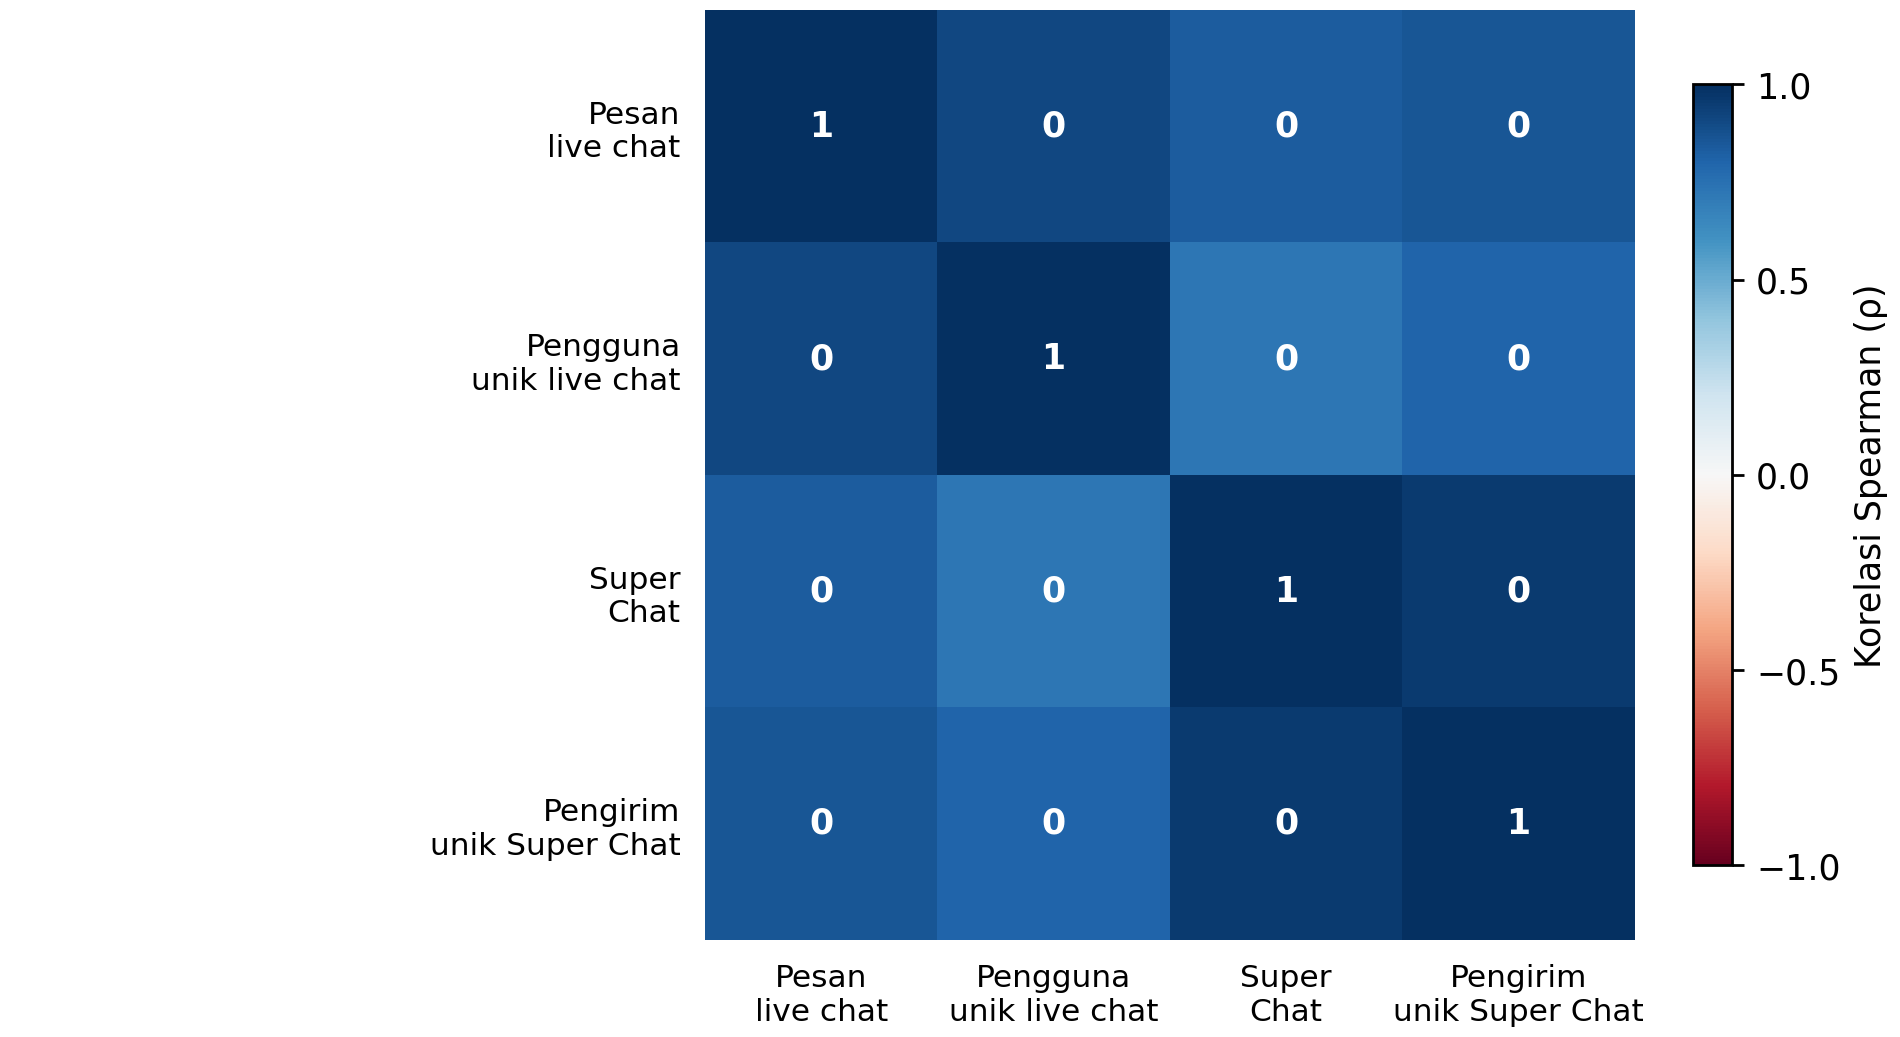

In [22]:
label_korelasi = {"chats": "Pesan live chat", "uniqueChatters": "Pengguna unik live chat",
                  "superChats": "Super Chat", "uniqueSuperChatters": "Pengirim unik Super Chat"}
data_korelasi = analysis[list(label_korelasi)].dropna()
korelasi = data_korelasi.corr(method="spearman")
print(f"Jumlah pengamatan untuk seluruh matriks = {angka_id(len(data_korelasi))}")
display(korelasi.rename(index=label_korelasi, columns=label_korelasi).round(3))
fig, ax = plt.subplots(figsize=(7.6, 4.15), layout="constrained")
heatmap = ax.imshow(korelasi, cmap="RdBu", vmin=-1, vmax=1)
labels = ["Pesan\nlive chat", "Pengguna\nunik live chat", "Super\nChat", "Pengirim\nunik Super Chat"]
ax.set_xticks(range(4), labels=labels)
ax.set_yticks(range(4), labels=labels)
ax.tick_params(length=0, pad=7, labelsize=9)
for baris in range(4):
    for kolom in range(4):
        nilai = korelasi.iloc[baris, kolom]
        ax.text(kolom, baris, angka_id(nilai, 3), ha="center", va="center",
                color="white" if abs(nilai) > 0.60 else "#172A38", fontweight="bold")
ax.spines[:].set_visible(False)
bar = fig.colorbar(heatmap, ax=ax, shrink=0.84, pad=0.03, ticks=[-1, -0.5, 0, 0.5, 1])
bar.set_label("Korelasi Spearman (ρ)")
simpan_gambar(fig, "Gambar_7_5_Heatmap_Spearman.png")

IQR & Zscore

In [23]:
label_variabel = {
    "uniqueChatters": "Pengguna unik live chat",
    "superChats": "Super Chat tercatat",
}
numerik = analysis[list(label_variabel)].astype(float)
q1 = numerik.quantile(0.25)
q3 = numerik.quantile(0.75)
iqr = q3 - q1
bawah_iqr, atas_iqr = q1 - 1.5 * iqr, q3 + 1.5 * iqr

rerata = numerik.mean()
simpangan = numerik.std(ddof=0)
z_score = (numerik - rerata) / simpangan
bawah_z, atas_z = rerata - 3 * simpangan, rerata + 3 * simpangan

pencilan_iqr = (numerik.lt(bawah_iqr) | numerik.gt(atas_iqr)).astype("boolean")
pencilan_iqr = pencilan_iqr.where(numerik.notna())
pencilan_z = z_score.abs().gt(3).astype("boolean").where(numerik.notna())

def ringkas_deteksi(batas_bawah, batas_atas, penanda):
    jumlah = penanda.sum()
    return pd.DataFrame({
        "Jumlah teramati": numerik.count(),
        "Batas bawah": batas_bawah,
        "Batas atas": batas_atas,
        "Jumlah pencilan": jumlah,
        "Persentase pencilan": 100 * jumlah / numerik.count(),
    }).rename_axis("Kolom")

tabel_8_1 = pd.concat({
    "IQR": ringkas_deteksi(bawah_iqr, atas_iqr, pencilan_iqr),
    "Z-score": ringkas_deteksi(bawah_z, atas_z, pencilan_z),
}, names=["Metode"]).reorder_levels(["Kolom", "Metode"]).sort_index()
display(tabel_8_1.rename(index=label_variabel, level="Kolom").round(2))

irisan_metode = pd.DataFrame({
    "IQR saja": (pencilan_iqr & ~pencilan_z).sum(),
    "Z-score saja": (pencilan_z & ~pencilan_iqr).sum(),
    "Keduanya": (pencilan_iqr & pencilan_z).sum(),
})
display(irisan_metode.rename(index=label_variabel))

Jumlah teramati  Batas bawah  Batas atas  \
Kolom                   Metode                                              
Super Chat tercatat     IQR                10941      -606.50     1117.50   
                        Z-score            10941     -3442.20     4500.22   
Pengguna unik live chat IQR                12468     -5459.62    10179.38   
                        Z-score            12468    -29421.02    40151.14   

                                 Jumlah pencilan  Persentase pencilan  
Kolom                   Metode                                         
Super Chat tercatat     IQR                 1240                11.33  
                        Z-score              184                 1.68  
Pengguna unik live chat IQR                 1792                14.37  
                        Z-score              299                  2.4

,IQR saja,Z-score saja,Keduanya
Pengguna unik live chat,1493,0,299
Super Chat tercatat,1056,0,184


Boxplot dan limit deteksi

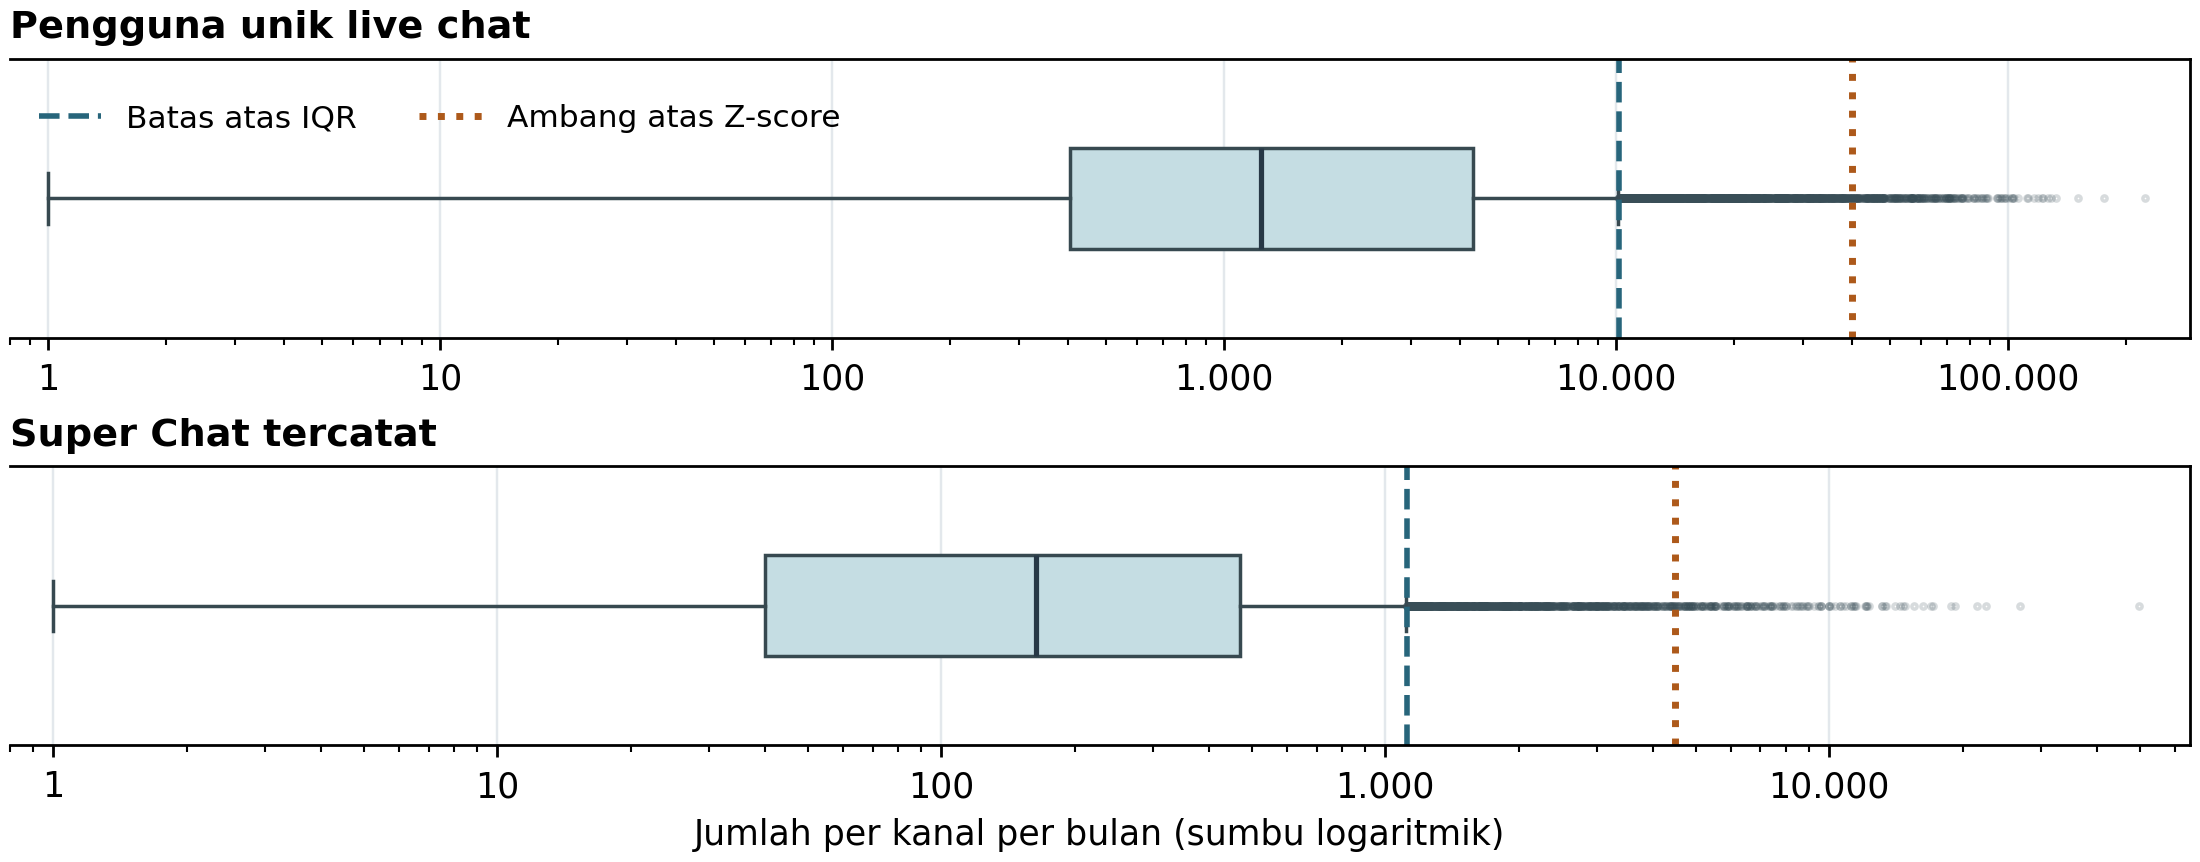

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(8.8, 3.45), layout="constrained")

for ax, (kolom, judul) in zip(axes, label_variabel.items()):
    nilai = numerik[kolom].dropna().to_numpy()
    ax.boxplot(
        nilai, orientation="horizontal", widths=0.36, whis=1.5, patch_artist=True,
        boxprops={"facecolor": "#C5DDE3", "edgecolor": "#374950"},
        whiskerprops={"color": "#374950"},
        capprops={"color": "#374950"},
        medianprops={"color": "#273846", "linewidth": 1.5},
        flierprops={"marker": ".", "markersize": 3, "markeredgecolor": "#394E57", "alpha": 0.20},
    )
    ax.axvline(atas_iqr[kolom], color=biru, linestyle="--", linewidth=1.6, label="Batas atas IQR")
    ax.axvline(atas_z[kolom], color=jingga, linestyle=":", linewidth=2.0, label="Ambang atas Z-score")
    ax.set(xscale="log", yticks=[], xlim=(0.8, nilai.max() * 1.3))
    ax.set_title(judul, fontweight="bold", loc="left", fontsize=11)
    ax.spines["left"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E3E8EC", linewidth=0.7)
    format_log(ax.xaxis)

axes[0].legend(loc="upper left", bbox_to_anchor=(0.0, 0.94), ncols=2, frameon=False, fontsize=9)
axes[-1].set_xlabel("Jumlah per kanal per bulan (sumbu logaritmik)")
simpan_gambar(fig, "Gambar_8_1_Deteksi_Pencilan.png")

Perbandingan Strategi

In [29]:
pasangan = numerik.dropna()
saring_iqr = pencilan_iqr.loc[pasangan.index].any(axis=1)
saring_z = pencilan_z.loc[pasangan.index].any(axis=1)

skenario = {
    "Retention (analisis utama)": pasangan,
    "Transformasi log1p": np.log1p(pasangan),
    "Trimming IQR": pasangan.loc[~saring_iqr],
    "Trimming Z-score": pasangan.loc[~saring_z],
    "Capping pada batas IQR": pasangan.clip(lower=bawah_iqr, upper=atas_iqr, axis=1),
}
tabel_8_2 = pd.DataFrame([
    {
        "Strategi": strategi,
        "Pasangan": len(data),
        "Spearman": data["uniqueChatters"].corr(data["superChats"], method="spearman"),
    }
    for strategi, data in skenario.items()
]).set_index("Strategi")
display(tabel_8_2.round(3))

,Pasangan,Spearman
Strategi,,
Retention (analisis utama),10941,0.723
Transformasi log1p,10941,0.723
Trimming IQR,8928,0.601
Trimming Z-score,10575,0.696
Capping pada batas IQR,10941,0.717
